# 05 – Uncertainty with Monte Carlo (MC) Dropout

**Goal:** give each patient a risk **range**, not just a single number, so doctors can see how confident the model is.

**Method:** keep dropout switched on at prediction time and run the GNN 100 times. The spread of the 100 predictions shows the model's uncertainty.

## Step 1 – Rebuild and train the GNN 

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import kneighbors_graph
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected
from torch_geometric.nn import GATConv

torch.manual_seed(42); np.random.seed(42)

# --- Data
df = pd.read_csv("../data/framingham.csv")
df.loc[(df.currentSmoker == 0) & (df.cigsPerDay.isna()), "cigsPerDay"] = 0
df = df.drop(columns=["education"])
X = df.drop(columns=["TenYearCHD"]); y = df["TenYearCHD"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_cal, X_test, y_cal, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
imp = SimpleImputer(strategy="median").fit(X_train)
sc = StandardScaler().fit(imp.transform(X_train))
X_all = pd.concat([X_train, X_cal, X_test]); y_all = pd.concat([y_train, y_cal, y_test])
Z = sc.transform(imp.transform(X_all)).astype("float32")
n, n_tr, n_cal = len(Z), len(X_train), len(X_cal)
train_mask = torch.zeros(n, dtype=torch.bool); train_mask[:n_tr] = True
cal_mask   = torch.zeros(n, dtype=torch.bool); cal_mask[n_tr:n_tr+n_cal] = True
test_mask  = torch.zeros(n, dtype=torch.bool); test_mask[n_tr+n_cal:] = True

# --- Graph
A = kneighbors_graph(Z, n_neighbors=10, include_self=False).tocoo()
edge_index = to_undirected(torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long))
graph = Data(x=torch.tensor(Z), edge_index=edge_index, y=torch.tensor(y_all.values, dtype=torch.float))

# --- Model
class GAT(torch.nn.Module):
    def __init__(self, in_dim, hidden=32):
        super().__init__()
        self.conv1 = GATConv(in_dim, hidden, heads=4, dropout=0.3)
        self.conv2 = GATConv(hidden * 4, 1, heads=1, dropout=0.3)
    def forward(self, x, edge_index):
        x = F.dropout(x, 0.3, self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, 0.3, self.training)
        return self.conv2(x, edge_index).squeeze(-1)

model = GAT(Z.shape[1])
opt = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
pos_weight = torch.tensor((y_train == 0).sum() / (y_train == 1).sum(), dtype=torch.float)

# --- Train (keep best epoch by calibration AUC)
best_auc, best_state = 0, None
for epoch in range(1, 301):
    model.train(); opt.zero_grad()
    out = model(graph.x, graph.edge_index)
    loss = F.binary_cross_entropy_with_logits(out[train_mask], graph.y[train_mask], pos_weight=pos_weight)
    loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(graph.x, graph.edge_index))
    cal_auc = roc_auc_score(graph.y[cal_mask], p[cal_mask])
    if cal_auc > best_auc:
        best_auc, best_state = cal_auc, {k: v.clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state); model.eval()
print("GNN trained. Calibration AUC:", round(best_auc, 3))

GNN trained. Calibration AUC: 0.676


## Step 2 – Run the GNN 100 times with dropout ON

`model.train()` keeps dropout active, so each run switches off different neurons and gives a slightly different prediction.

In [2]:
T = 100
model.train()                       # dropout ON
torch.manual_seed(0)
with torch.no_grad():
    samples = torch.stack([model(graph.x, graph.edge_index) for _ in range(T)])   # shape [100, 4238]
model.eval()                        # back to normal
print(samples.shape)

torch.Size([100, 4238])


## Step 3 – Calibrate and build a risk range for each patient

- **Platt scaling** (as in notebook 01) turns raw scores into realistic percentages, learned on the calibration set
- For each patient: **mean** of the 100 predictions = risk; **5th–95th percentile** = likely range (90% interval)

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

mean_logit = samples.mean(0)
platt = LogisticRegression().fit(mean_logit[cal_mask].numpy().reshape(-1, 1),
                                 graph.y[cal_mask].numpy())
a, b = platt.coef_[0, 0], platt.intercept_[0]

probs = torch.sigmoid(a * samples + b)       # calibrated risk for each of the 100 runs
risk    = probs.mean(0)
risk_lo = probs.quantile(0.05, dim=0)
risk_hi = probs.quantile(0.95, dim=0)

y_test_np = graph.y[test_mask].numpy()
print("Test AUC:", round(roc_auc_score(y_test_np, risk[test_mask]), 3))
print("Brier score:", round(brier_score_loss(y_test_np, risk[test_mask]), 3))

results = pd.DataFrame({
    "risk_%":  (risk[test_mask] * 100).numpy(),
    "low_%":   (risk_lo[test_mask] * 100).numpy(),
    "high_%":  (risk_hi[test_mask] * 100).numpy(),
    "actual_CHD": y_test_np.astype(int),
})
results["range_width"] = results["high_%"] - results["low_%"]
print("Median range width:", round(results["range_width"].median(), 1), "percentage points")
results.sort_values("risk_%", ascending=False).head(5).round(1)

Test AUC: 0.691
Brier score: 0.12
Median range width: 4.6 percentage points


,risk_%,low_%,high_%,actual_CHD,range_width
190,53.599998,34.400002,72.599998,1,38.099998
696,50.299999,32.799999,68.699997,1,36.000000
460,46.000000,34.099998,58.000000,1,23.900000
690,44.200001,35.000000,55.700001,0,20.700001
847,41.200001,32.400002,50.400002,1,18.000000


## Step 4 – Does uncertainty mean anything?

Split test patients into 3 equal groups by range width (low / medium / high uncertainty) and compare how often the model is right (flag "high risk" at ≥ 15%).

In [4]:
results["flag_high_risk"] = (results["risk_%"] >= 15).astype(int)
results["correct"] = (results["flag_high_risk"] == results["actual_CHD"]).astype(int)
results["uncertainty"] = pd.qcut(results["range_width"], 3, labels=["low", "medium", "high"])

results.groupby("uncertainty", observed=True).agg(
    patients=("correct", "size"),
    avg_range_width=("range_width", "mean"),
    accuracy=("correct", "mean"),
    avg_risk=("risk_%", "mean"),
).round(2)

,patients,avg_range_width,accuracy,avg_risk
uncertainty,,,,
low,283,3.61,0.85,9.800000
medium,282,4.69,0.71,11.710000
high,283,10.04,0.31,23.620001


## Step 5 – Plot: risk with uncertainty range

Each line is one patient's 90% range; the dot is their risk. Red = developed CHD.

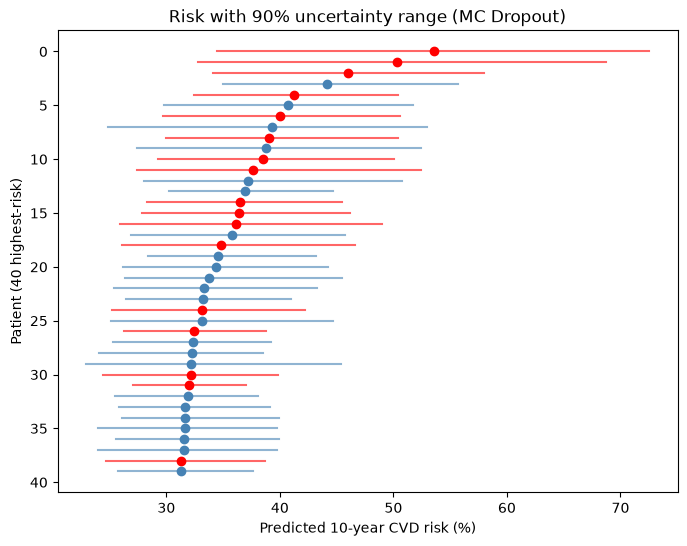

In [5]:
import matplotlib.pyplot as plt

top = results.sort_values("risk_%", ascending=False).head(40).reset_index(drop=True)
colors = ["red" if v == 1 else "steelblue" for v in top["actual_CHD"]]

plt.figure(figsize=(8, 6))
for i, r in top.iterrows():
    plt.plot([r["low_%"], r["high_%"]], [i, i], color=colors[i], alpha=0.6)
    plt.plot(r["risk_%"], i, "o", color=colors[i])
plt.gca().invert_yaxis()
plt.xlabel("Predicted 10-year CVD risk (%)"); plt.ylabel("Patient (40 highest-risk)")
plt.title("Risk with 90% uncertainty range (MC Dropout)")
plt.savefig("../outputs/mc_dropout_ranges.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- MC Dropout (100 runs) gives each patient a **risk range** – e.g. 54% (34–72%)
- Accuracy unchanged (AUC 0.691) and well calibrated (Brier 0.120)
- **Uncertainty is informative:** model is right 85% of the time for low-uncertainty patients vs 31% for high-uncertainty patients
- Clinical use: wide-range predictions are flagged for doctor review instead of being trusted automatically
- Caveat: high-uncertainty patients also tend to be higher-risk, which partly explains the accuracy gap